In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import signal
from scipy.signal import butter, filtfilt, welch

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tqdm.auto import tqdm

import pywt

plt.style.use("seaborn-v0_8-whitegrid")

# ============================================================
# Canva slide theme (matches "EEG-Based Seizure Detection Using
# Hybrid Quantum Machine Learning" slide deck — beige & white)
# ============================================================
from matplotlib.colors import LinearSegmentedColormap

CANVA_CREAM      = "#FBF6EC"
CANVA_BEIGE      = "#EFE0C0"
CANVA_TAN        = "#D9B98C"
CANVA_GOLD       = "#C9A876"
CANVA_BROWN      = "#8B6F4E"
CANVA_DARK_BROWN = "#5C4530"
CANVA_DARKEST    = "#3E2F22"

CANVA_PALETTE = [
    CANVA_DARK_BROWN,
    CANVA_BROWN,
    CANVA_GOLD,
    CANVA_TAN,
    CANVA_BEIGE,
]

CANVA_SEQ_CMAP = LinearSegmentedColormap.from_list(
    "canva_seq",
    [
        CANVA_CREAM,
        CANVA_BEIGE,
        CANVA_TAN,
        CANVA_GOLD,
        CANVA_BROWN,
        CANVA_DARK_BROWN,
        CANVA_DARKEST,
    ],
)

CANVA_DIV_CMAP = LinearSegmentedColormap.from_list(
    "canva_div",
    [CANVA_DARK_BROWN, CANVA_CREAM, CANVA_GOLD],
)

sns.set_palette(CANVA_PALETTE)

plt.rcParams.update({
    "figure.facecolor": CANVA_CREAM,
    "axes.facecolor": CANVA_CREAM,
    "savefig.facecolor": CANVA_CREAM,
    "axes.edgecolor": CANVA_TAN,
    "axes.labelcolor": CANVA_DARK_BROWN,
    "axes.titlecolor": CANVA_DARK_BROWN,
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "text.color": CANVA_DARK_BROWN,
    "xtick.color": CANVA_DARK_BROWN,
    "ytick.color": CANVA_DARK_BROWN,
    "grid.color": CANVA_BEIGE,
    "grid.alpha": 0.7,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.grid": True,
})

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment initialized successfully.")

Environment initialized successfully.


In [2]:
# ============================================================
# EEG PROJECT CONFIGURATION
# ============================================================

DATA_PATH = r"C:\Users\devgo\OneDrive\Desktop\mini project\Data\EEG_Scaled_data.csv"

# Original CHB-MIT sampling rate
FS = 256

# Filtering
LOWCUT = 0.5
HIGHCUT = 45.0
FILTER_ORDER = 4

# Segmentation
WINDOW_SECONDS = 4
OVERLAP = 0.50

WINDOW_SAMPLES = int(FS * WINDOW_SECONDS)
STEP_SAMPLES = int(WINDOW_SAMPLES * (1 - OVERLAP))

# Random seed
RANDOM_STATE = 42

print("=" * 60)
print("PROJECT CONFIGURATION")
print("=" * 60)

print(f"Dataset path       : {DATA_PATH}")
print(f"Sampling frequency : {FS} Hz")
print(f"Bandpass filter    : {LOWCUT} - {HIGHCUT} Hz")
print(f"Filter order       : {FILTER_ORDER}")
print(f"Window duration    : {WINDOW_SECONDS} seconds")
print(f"Window samples     : {WINDOW_SAMPLES}")
print(f"Overlap            : {OVERLAP * 100:.0f}%")
print(f"Step size          : {STEP_SAMPLES} samples")

PROJECT CONFIGURATION
Dataset path       : C:\Users\devgo\OneDrive\Desktop\mini project\Data\EEG_Scaled_data.csv
Sampling frequency : 256 Hz
Bandpass filter    : 0.5 - 45.0 Hz
Filter order       : 4
Window duration    : 4 seconds
Window samples     : 1024
Overlap            : 50%
Step size          : 512 samples


In [3]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )

file_size_mb = os.path.getsize(DATA_PATH) / (1024 ** 2)

print("Dataset found successfully.")
print(f"File size: {file_size_mb:.2f} MB")

Dataset found successfully.
File size: 2524.45 MB


In [4]:
print("Loading EEG dataset...")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print()
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")
print(f"Memory  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Loading EEG dataset...


Dataset loaded successfully.

Rows    : 11,233
Columns : 36,865
Memory  : 3159.37 MB


In [5]:
print("Column names:")
print(df.columns[:10].tolist())

print("\nLast columns:")
print(df.columns[-10:].tolist())

Column names:
['Channel_1', 'Channel_2', 'Channel_3', 'Channel_4', 'Channel_5', 'Channel_6', 'Channel_7', 'Channel_8', 'Channel_9', 'Channel_10']

Last columns:
['Channel_36856', 'Channel_36857', 'Channel_36858', 'Channel_36859', 'Channel_36860', 'Channel_36861', 'Channel_36862', 'Channel_36863', 'Channel_36864', 'target']


In [6]:
TARGET_COL = "target"

if TARGET_COL not in df.columns:
    raise ValueError(
        f"Expected target column '{TARGET_COL}' was not found."
    )

SIGNAL_COLUMNS = [
    col for col in df.columns
    if col != TARGET_COL
]

print("=" * 60)
print("DATASET STRUCTURE")
print("=" * 60)

print(f"Observations          : {len(df):,}")
print(f"Signal columns        : {len(SIGNAL_COLUMNS):,}")
print(f"Target column         : {TARGET_COL}")

duration_seconds = len(SIGNAL_COLUMNS) / FS

print(f"\nAssuming FS = {FS} Hz:")
print(f"Samples per observation: {len(SIGNAL_COLUMNS):,}")
print(f"Duration per row       : {duration_seconds:.2f} sec")
print(f"Duration per row       : {duration_seconds / 60:.2f} min")

DATASET STRUCTURE
Observations          : 11,233
Signal columns        : 36,864
Target column         : target

Assuming FS = 256 Hz:
Samples per observation: 36,864
Duration per row       : 144.00 sec
Duration per row       : 2.40 min


In [7]:
print("DATA TYPES")
print("=" * 60)

display(
    df.dtypes.value_counts().to_frame("count")
)

DATA TYPES


,count
float64,36864
int64,1


In [8]:
missing_total = df.isnull().sum().sum()

print("=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)

print(f"Total missing values: {missing_total:,}")

MISSING VALUE ANALYSIS
Total missing values: 0


In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0]

if len(missing) > 0:
    display(
        missing.sort_values(
            ascending=False
        ).to_frame("missing_count")
    )
else:
    print("No missing values detected.")

No missing values detected.


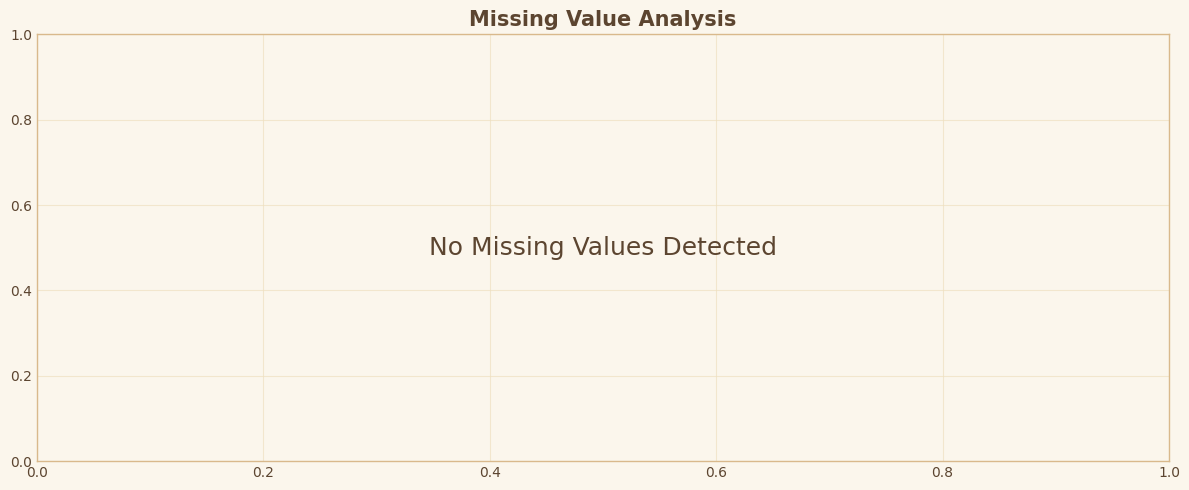

In [10]:
plt.figure(figsize=(12, 5))

if len(missing) > 0:

    missing.sort_values(
        ascending=False
    ).head(30).plot(kind="bar", color=CANVA_BROWN)

    plt.title("Missing Values by Feature")
    plt.xlabel("Feature")
    plt.ylabel("Missing Values")

else:

    plt.text(
        0.5,
        0.5,
        "No Missing Values Detected",
        ha="center",
        va="center",
        fontsize=18
    )

    plt.title("Missing Value Analysis")

plt.tight_layout()
plt.show()

In [11]:
print("=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

target_counts = (
    df[TARGET_COL]
    .value_counts()
    .sort_index()
)

target_percent = (
    df[TARGET_COL]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
})

display(target_summary)

TARGET DISTRIBUTION


,Count,Percentage
target,,
0,9799,87.23
1,1434,12.77


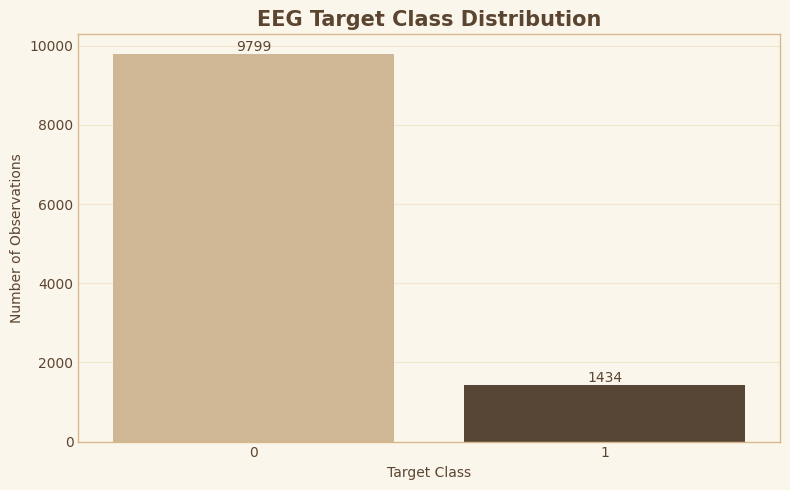

In [12]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=TARGET_COL,
    order=sorted(df[TARGET_COL].unique()),
    palette=[CANVA_TAN, CANVA_DARK_BROWN]
)

plt.title("EEG Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Observations")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [13]:
class_counts = df[TARGET_COL].value_counts()

if len(class_counts) >= 2:

    majority_class = class_counts.idxmax()
    minority_class = class_counts.idxmin()

    imbalance_ratio = (
        class_counts[majority_class] /
        class_counts[minority_class]
    )

    print(f"Majority class : {majority_class}")
    print(f"Minority class : {minority_class}")
    print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

else:

    print(
        "Only one class is present in this file/sample."
    )

Majority class : 0
Minority class : 1
Imbalance ratio: 6.83:1


In [14]:
signal_data = df[SIGNAL_COLUMNS]

print("=" * 60)
print("SIGNAL STATISTICS")
print("=" * 60)

display(
    signal_data.describe().T.head(20)
)

SIGNAL STATISTICS


,count,mean,std,min,25%,50%,75%,max
Channel_1,11233.0,-3.560937e-07,1.000049,-14.591,-0.197,-0.004,0.193,11.549
Channel_2,11233.0,-5.697498e-06,1.000038,-14.564,-0.213,-0.007,0.191,10.703
Channel_3,11233.0,6.765779e-06,1.000041,-15.325,-0.210,-0.005,0.188,9.743
Channel_4,11233.0,-1.246328e-06,1.000041,-14.391,-0.202,0.003,0.193,9.812
Channel_5,11233.0,-6.409686e-06,1.000044,-13.434,-0.196,0.012,0.201,11.948
Channel_6,11233.0,-7.121873e-07,1.000047,-12.313,-0.191,0.016,0.204,13.850
Channel_7,11233.0,-1.557910e-05,1.000045,-11.966,-0.197,0.008,0.204,14.387
Channel_8,11233.0,2.492656e-06,1.000036,-14.911,-0.204,0.005,0.198,13.479
Channel_9,11233.0,-2.314609e-06,1.000053,-15.195,-0.207,-0.004,0.188,13.708
Channel_10,11233.0,3.026796e-06,1.000042,-14.194,-0.209,-0.011,0.180,15.914


In [15]:
all_values = signal_data.values.astype(np.float32)

print("=" * 60)
print("GLOBAL EEG STATISTICS")
print("=" * 60)

print(f"Global minimum : {np.nanmin(all_values):.6f}")
print(f"Global maximum : {np.nanmax(all_values):.6f}")
print(f"Global mean    : {np.nanmean(all_values):.6f}")
print(f"Global std     : {np.nanstd(all_values):.6f}")
print(f"Global median  : {np.nanmedian(all_values):.6f}")

GLOBAL EEG STATISTICS
Global minimum : -31.518000
Global maximum : 34.069000
Global mean    : 0.000000
Global std     : 1.000002
Global median  : 0.000000


In [16]:
all_values = signal_data.values.astype(np.float32)

print("=" * 60)
print("GLOBAL EEG STATISTICS")
print("=" * 60)

print(f"Global minimum : {np.nanmin(all_values):.6f}")
print(f"Global maximum : {np.nanmax(all_values):.6f}")
print(f"Global mean    : {np.nanmean(all_values):.6f}")
print(f"Global std     : {np.nanstd(all_values):.6f}")
print(f"Global median  : {np.nanmedian(all_values):.6f}")

GLOBAL EEG STATISTICS
Global minimum : -31.518000
Global maximum : 34.069000
Global mean    : 0.000000
Global std     : 1.000002
Global median  : 0.000000


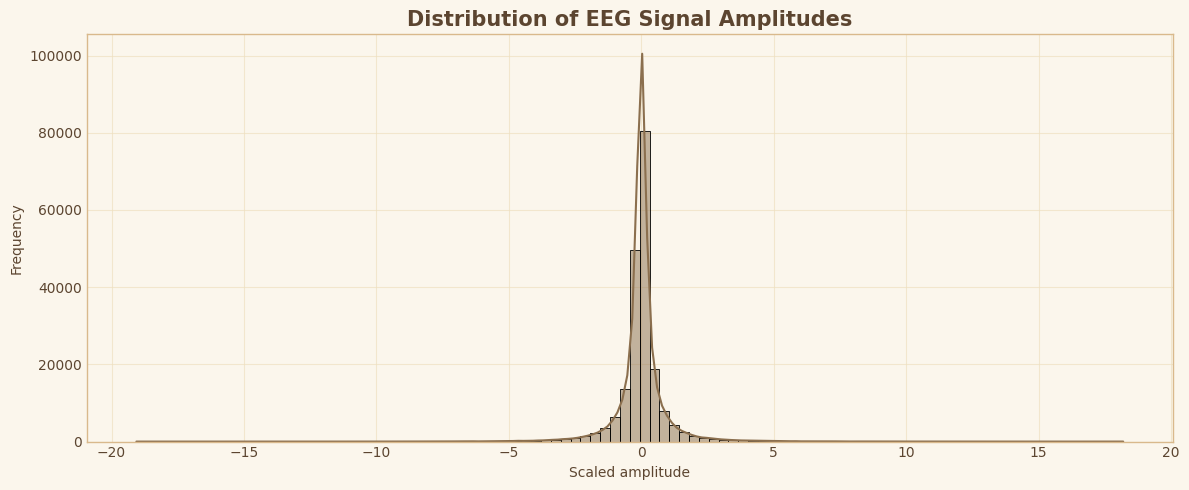

In [17]:
# Randomly sample values to keep plotting efficient
rng = np.random.default_rng(RANDOM_STATE)

flat_values = all_values.ravel()

sample_size = min(
    200_000,
    len(flat_values)
)

sample_values = rng.choice(
    flat_values,
    size=sample_size,
    replace=False
)

plt.figure(figsize=(12, 5))

sns.histplot(
    sample_values,
    bins=100,
    kde=True,
    color=CANVA_BROWN,
    line_kws={"color": CANVA_DARK_BROWN}
)

plt.title("Distribution of EEG Signal Amplitudes")
plt.xlabel("Scaled amplitude")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [18]:
SAMPLE_INDEX = 0

eeg_signal = (
    df.loc[
        SAMPLE_INDEX,
        SIGNAL_COLUMNS
    ]
    .values
    .astype(np.float32)
)

time = np.arange(
    len(eeg_signal)
) / FS

print(f"Selected observation : {SAMPLE_INDEX}")
print(f"Number of samples    : {len(eeg_signal):,}")
print(f"Duration             : {len(eeg_signal)/FS:.2f} seconds")
print(f"Target               : {df.loc[SAMPLE_INDEX, TARGET_COL]}")

Selected observation : 0
Number of samples    : 36,864
Duration             : 144.00 seconds
Target               : 0


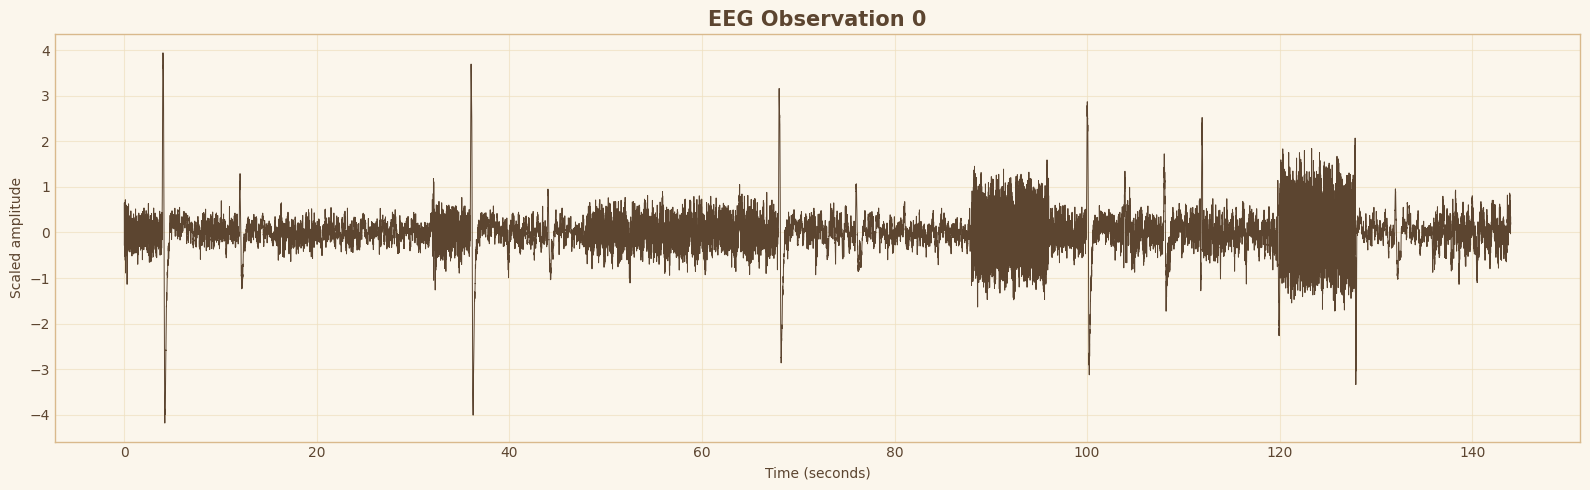

In [19]:
plt.figure(figsize=(16, 5))

plt.plot(
    time,
    eeg_signal,
    linewidth=0.7,
    color=CANVA_DARK_BROWN
)

plt.title(
    f"EEG Observation {SAMPLE_INDEX}"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Scaled amplitude")

plt.tight_layout()
plt.show()

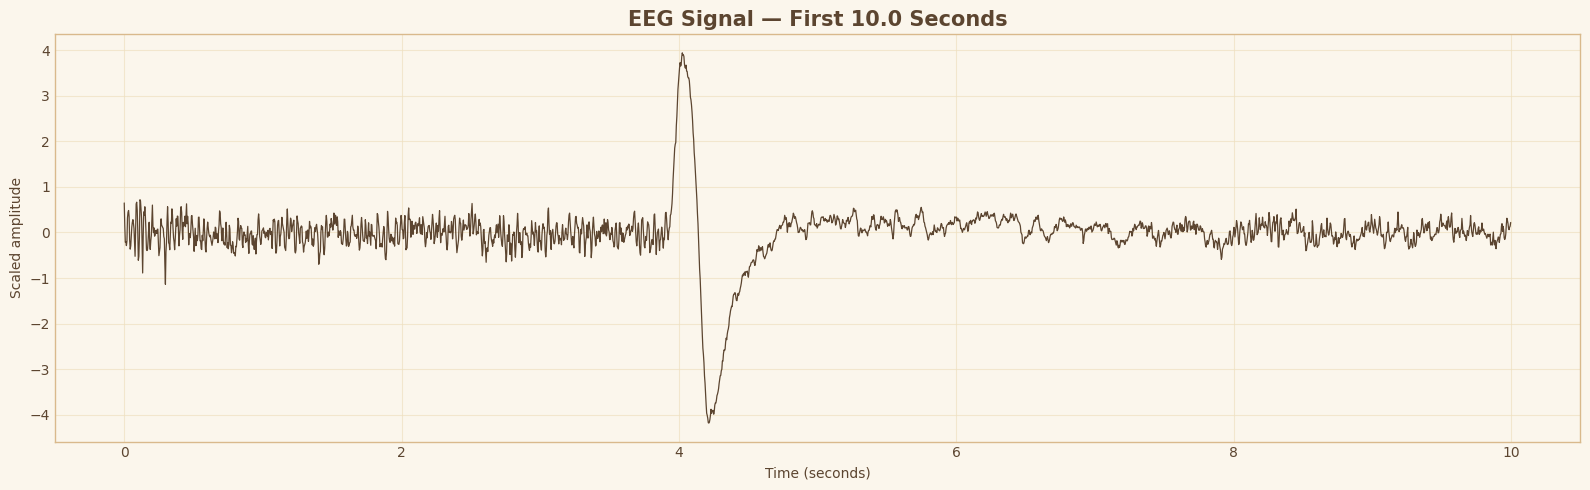

In [20]:
DISPLAY_SECONDS = 10

n_samples_display = min(
    int(DISPLAY_SECONDS * FS),
    len(eeg_signal)
)

plt.figure(figsize=(16, 5))

plt.plot(
    time[:n_samples_display],
    eeg_signal[:n_samples_display],
    linewidth=0.9,
    color=CANVA_DARK_BROWN
)

plt.title(
    f"EEG Signal — First {n_samples_display / FS:.1f} Seconds"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Scaled amplitude")

plt.tight_layout()
plt.show()

In [21]:
def design_bandpass_filter(
    lowcut,
    highcut,
    fs,
    order=4
):
    
    nyquist = 0.5 * fs
    
    low = lowcut / nyquist
    high = highcut / nyquist

    b, a = butter(
        order,
        [low, high],
        btype="band"
    )

    return b, a


def bandpass_filter(
    x,
    lowcut=0.5,
    highcut=45.0,
    fs=256,
    order=4
):
    
    b, a = design_bandpass_filter(
        lowcut,
        highcut,
        fs,
        order
    )

    return filtfilt(
        b,
        a,
        x
    )

In [22]:
filtered_signal = bandpass_filter(
    eeg_signal,
    lowcut=LOWCUT,
    highcut=HIGHCUT,
    fs=FS,
    order=FILTER_ORDER
)

print("Bandpass filtering completed.")

Bandpass filtering completed.


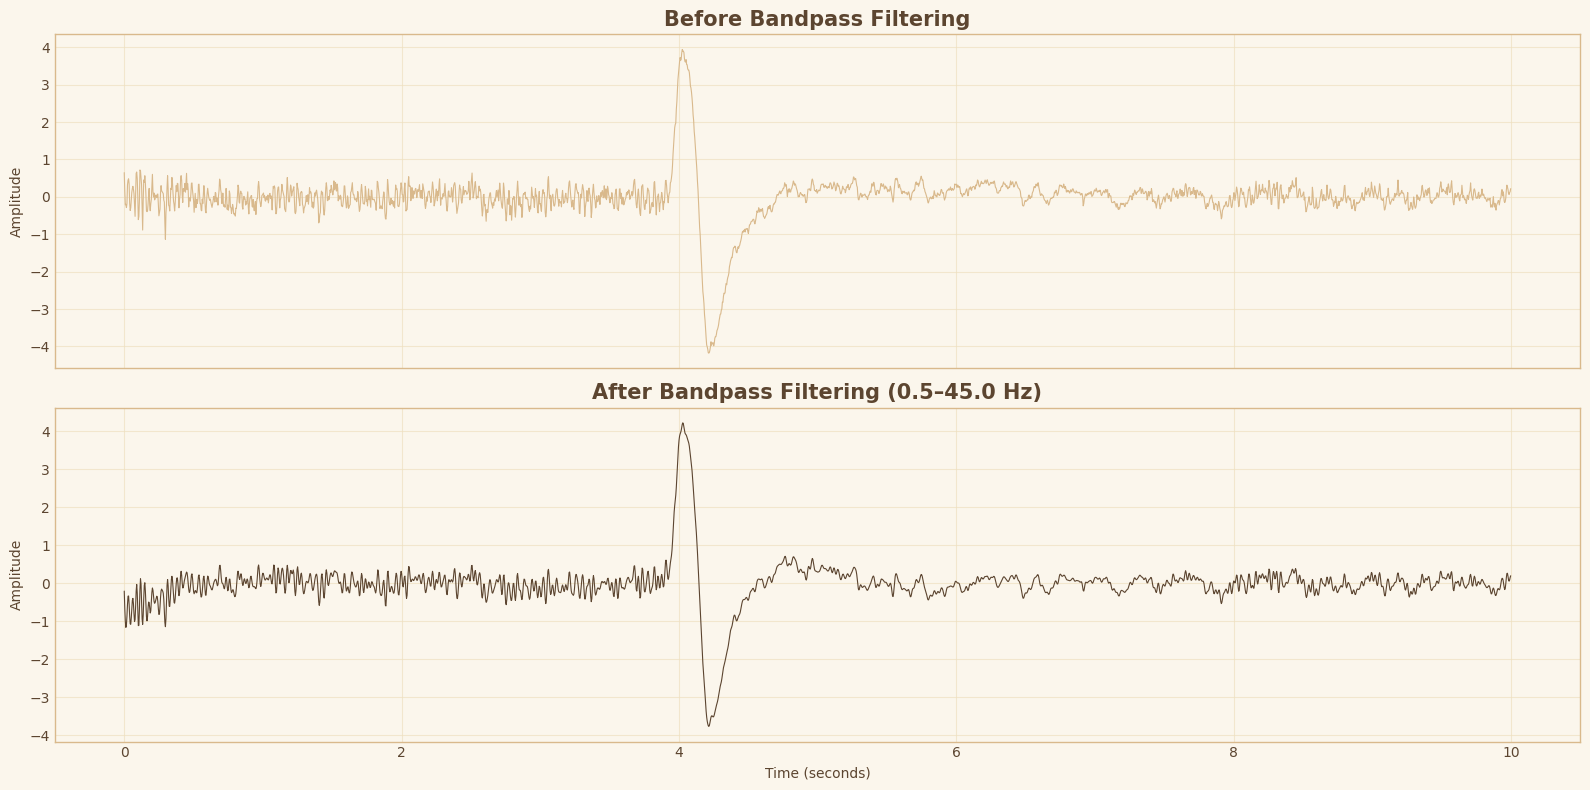

In [23]:
DISPLAY_SECONDS = 10

n = min(
    int(DISPLAY_SECONDS * FS),
    len(eeg_signal)
)

time_display = np.arange(n) / FS

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 8),
    sharex=True
)

axes[0].plot(
    time_display,
    eeg_signal[:n],
    linewidth=0.8,
    color=CANVA_TAN
)

axes[0].set_title(
    "Before Bandpass Filtering"
)

axes[0].set_ylabel(
    "Amplitude"
)

axes[1].plot(
    time_display,
    filtered_signal[:n],
    linewidth=0.8,
    color=CANVA_DARK_BROWN
)

axes[1].set_title(
    f"After Bandpass Filtering ({LOWCUT}–{HIGHCUT} Hz)"
)

axes[1].set_xlabel(
    "Time (seconds)"
)

axes[1].set_ylabel(
    "Amplitude"
)

plt.tight_layout()
plt.show()

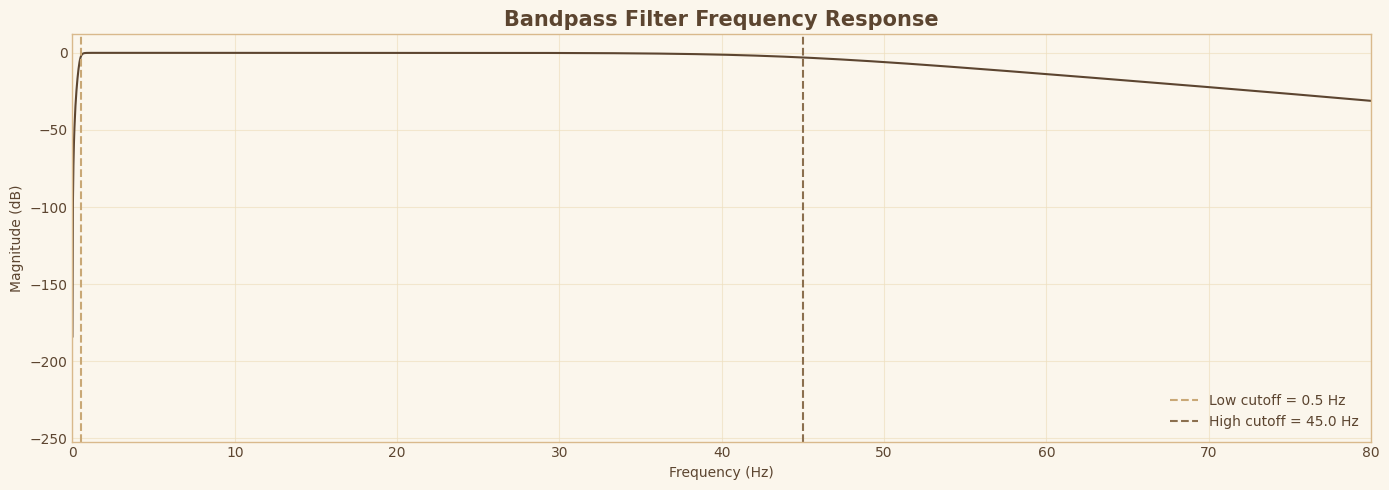

In [24]:
b, a = design_bandpass_filter(
    LOWCUT,
    HIGHCUT,
    FS,
    FILTER_ORDER
)

frequencies, response = signal.freqz(
    b,
    a,
    worN=4096,
    fs=FS
)

magnitude_db = 20 * np.log10(
    np.maximum(
        np.abs(response),
        1e-12
    )
)

plt.figure(figsize=(14, 5))

plt.plot(
    frequencies,
    magnitude_db,
    linewidth=1.5,
    color=CANVA_DARK_BROWN
)

plt.axvline(
    LOWCUT,
    linestyle="--",
    label=f"Low cutoff = {LOWCUT} Hz",
    color=CANVA_GOLD
)

plt.axvline(
    HIGHCUT,
    linestyle="--",
    label=f"High cutoff = {HIGHCUT} Hz",
    color=CANVA_BROWN
)

plt.xlim(0, 80)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

plt.title(
    "Bandpass Filter Frequency Response"
)

plt.legend()

plt.tight_layout()
plt.show()

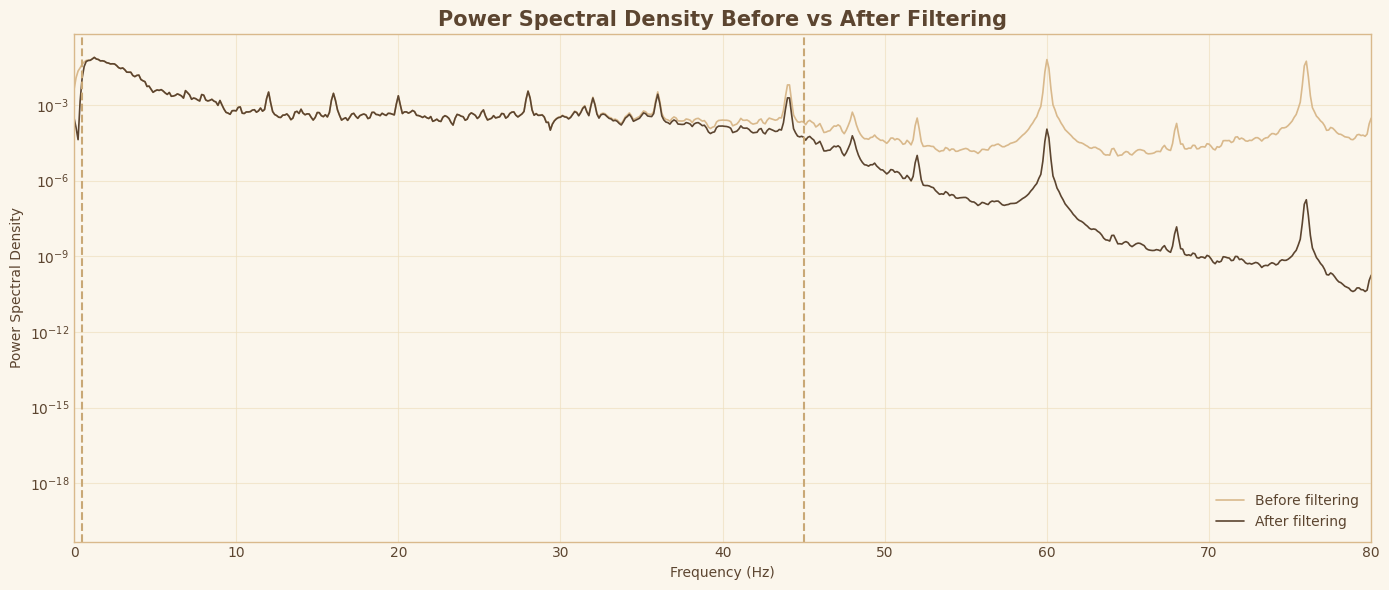

In [25]:
f_raw, psd_raw = welch(
    eeg_signal,
    fs=FS,
    nperseg=min(2048, len(eeg_signal))
)

f_filtered, psd_filtered = welch(
    filtered_signal,
    fs=FS,
    nperseg=min(2048, len(filtered_signal))
)

plt.figure(figsize=(14, 6))

plt.semilogy(
    f_raw,
    psd_raw,
    label="Before filtering",
    linewidth=1.2,
    color=CANVA_TAN
)

plt.semilogy(
    f_filtered,
    psd_filtered,
    label="After filtering",
    linewidth=1.2,
    color=CANVA_DARK_BROWN
)

plt.axvline(
    LOWCUT,
    linestyle="--",
    color=CANVA_GOLD
)

plt.axvline(
    HIGHCUT,
    linestyle="--",
    color=CANVA_GOLD
)

plt.xlim(0, 80)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")

plt.title(
    "Power Spectral Density Before vs After Filtering"
)

plt.legend()

plt.tight_layout()
plt.show()

In [26]:
EEG_BANDS = {
    "Delta": (0.5, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta": (13, 30),
    "Gamma": (30, 45)
}

print("EEG frequency bands:")
for band, (low, high) in EEG_BANDS.items():
    print(f"{band:8s}: {low:5.1f} – {high:5.1f} Hz")

EEG frequency bands:
Delta   :   0.5 –   4.0 Hz
Theta   :   4.0 –   8.0 Hz
Alpha   :   8.0 –  13.0 Hz
Beta    :  13.0 –  30.0 Hz
Gamma   :  30.0 –  45.0 Hz


In [27]:
def calculate_band_power(
    x,
    fs,
    bands
):

    f, psd = welch(
        x,
        fs=fs,
        nperseg=min(2048, len(x))
    )

    results = {}

    for band, (low, high) in bands.items():

        mask = (
            (f >= low) &
            (f <= high)
        )

        if np.any(mask):

            power = np.trapezoid(
                psd[mask],
                f[mask]
            )

        else:

            power = 0.0

        results[band] = power

    return results

In [28]:
band_power = calculate_band_power(
    filtered_signal,
    FS,
    EEG_BANDS
)

band_power_df = pd.DataFrame(
    {
        "Band": list(band_power.keys()),
        "Power": list(band_power.values())
    }
)

display(
    band_power_df.round(6)
)

,Band,Power
0,Delta,0.141698
1,Theta,0.014963
2,Alpha,0.004373
3,Beta,0.008241
4,Gamma,0.004881


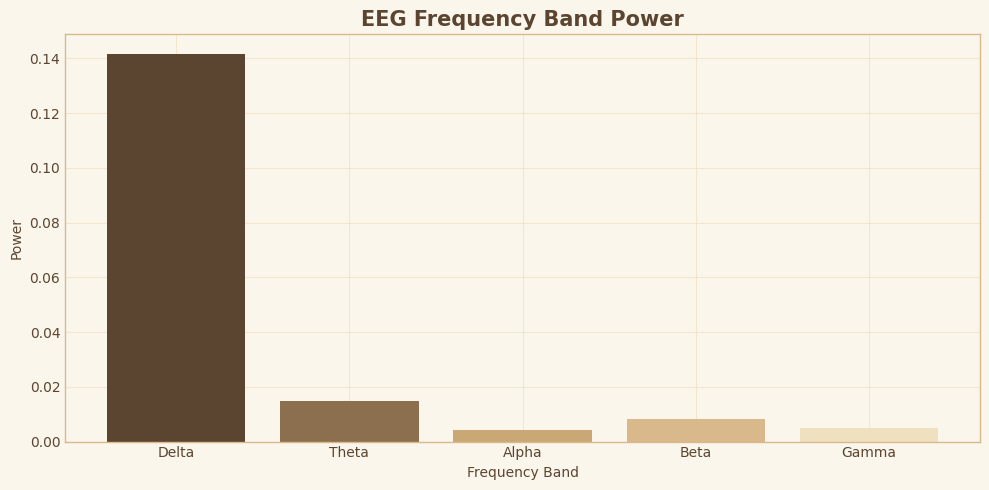

In [29]:
plt.figure(figsize=(10, 5))

plt.bar(
    band_power.keys(),
    band_power.values(),
    color=CANVA_PALETTE[:len(band_power)]
)

plt.title(
    "EEG Frequency Band Power"
)

plt.xlabel(
    "Frequency Band"
)

plt.ylabel(
    "Power"
)

plt.tight_layout()
plt.show()

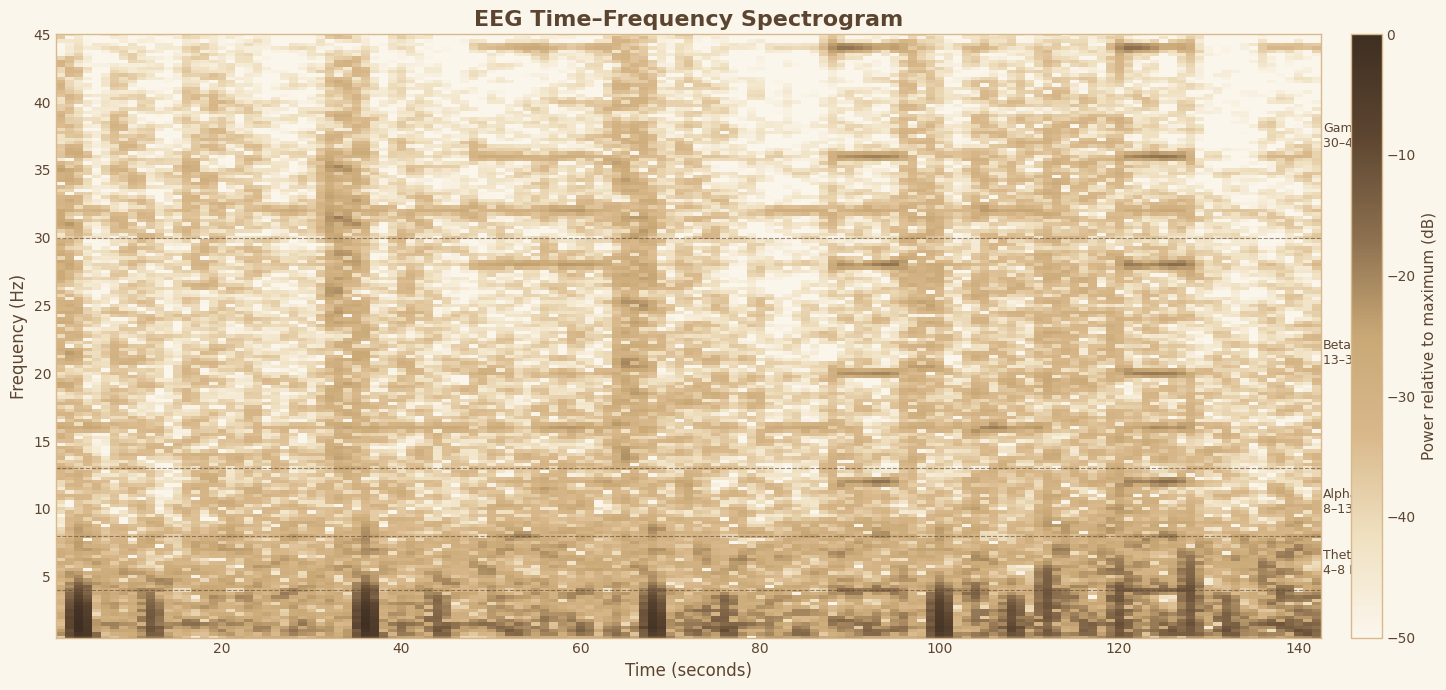

In [30]:
# ============================================================
# IMPROVED EEG SPECTROGRAM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

FS = 256

SPEC_WINDOW_SECONDS = 4
SPEC_OVERLAP = 0.75

SPEC_NPERSEG = int(
    FS * SPEC_WINDOW_SECONDS
)

SPEC_NOVERLAP = int(
    SPEC_NPERSEG * SPEC_OVERLAP
)

# Frequency range to display
FREQ_MIN = 0.5
FREQ_MAX = 45

# ------------------------------------------------------------
# Compute spectrogram
# ------------------------------------------------------------

f_spec, t_spec, Sxx = signal.spectrogram(
    filtered_signal,
    fs=FS,
    window="hann",
    nperseg=SPEC_NPERSEG,
    noverlap=SPEC_NOVERLAP,
    scaling="density",
    mode="psd"
)

# Keep only EEG frequency range
freq_mask = (
    (f_spec >= FREQ_MIN) &
    (f_spec <= FREQ_MAX)
)

f_plot = f_spec[freq_mask]
Sxx_plot = Sxx[freq_mask, :]

# ------------------------------------------------------------
# Convert power to dB
# ------------------------------------------------------------

Sxx_dB = 10 * np.log10(
    Sxx_plot + 1e-12
)

# Normalize relative to maximum power
Sxx_dB = Sxx_dB - np.max(Sxx_dB)

# Dynamic range
VMIN = -50
VMAX = 0

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(16, 7)
)

mesh = ax.pcolormesh(
    t_spec,
    f_plot,
    Sxx_dB,
    shading="auto",
    cmap=CANVA_SEQ_CMAP,
    vmin=VMIN,
    vmax=VMAX
)

# ------------------------------------------------------------
# EEG frequency bands
# ------------------------------------------------------------

bands = {
    "Delta\n0.5–4 Hz": (0.5, 4),
    "Theta\n4–8 Hz": (4, 8),
    "Alpha\n8–13 Hz": (8, 13),
    "Beta\n13–30 Hz": (13, 30),
    "Gamma\n30–45 Hz": (30, 45)
}

for name, (low, high) in bands.items():

    ax.axhline(
        low,
        linestyle="--",
        linewidth=0.8,
        alpha=0.6,
        color=CANVA_DARK_BROWN
    )

    if low != 0.5:
        ax.text(
            t_spec[-1] * 1.005,
            (low + high) / 2,
            name,
            va="center",
            fontsize=9
        )

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_title(
    "EEG Time–Frequency Spectrogram",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel(
    "Time (seconds)",
    fontsize=12
)

ax.set_ylabel(
    "Frequency (Hz)",
    fontsize=12
)

ax.set_ylim(
    FREQ_MIN,
    FREQ_MAX
)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    mesh,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Power relative to maximum (dB)",
    fontsize=11
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    True,
    linestyle=":",
    alpha=0.25
)

plt.tight_layout()
plt.show()

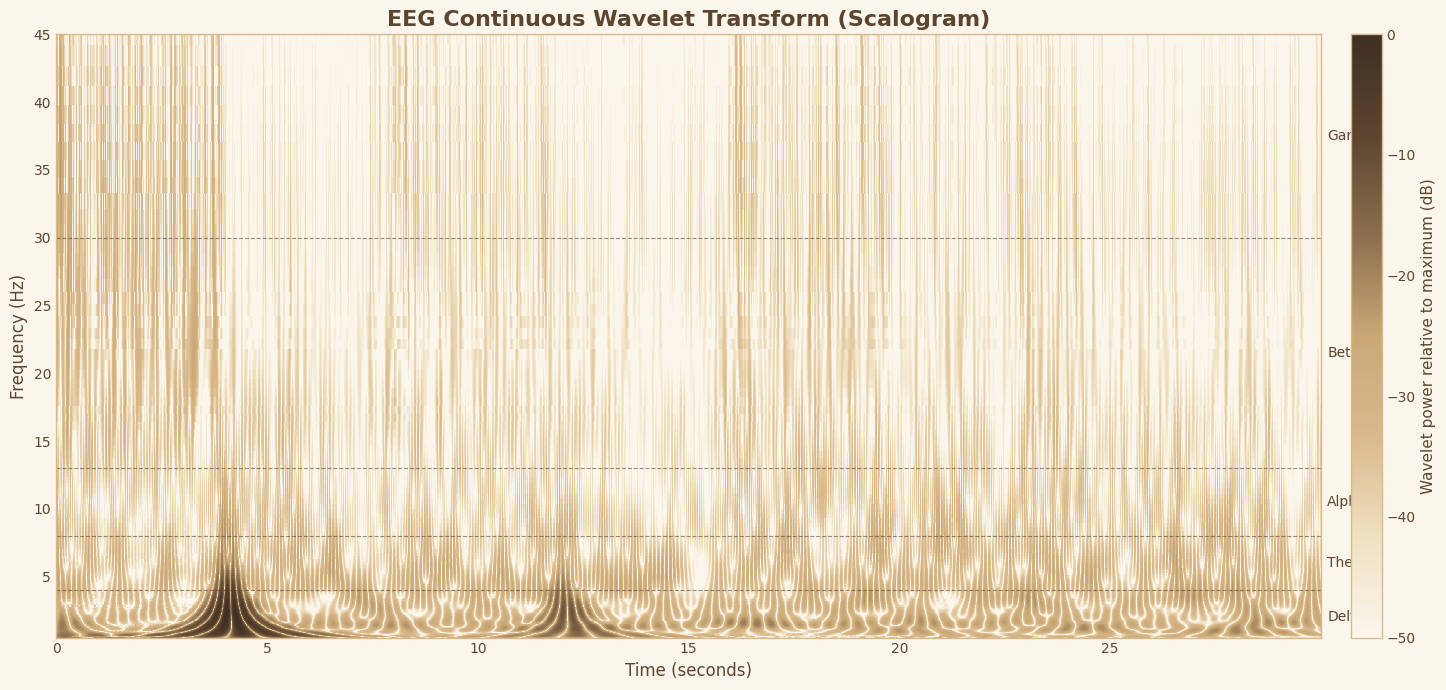

In [31]:
# ============================================================
# IMPROVED EEG WAVELET SCALOGRAM
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pywt

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

FS = 256

WAVELET = "morl"

FREQ_MIN = 0.5
FREQ_MAX = 45

# Analyze first N seconds
# Use the complete signal if you want the full recording
DISPLAY_SECONDS = 30

N_SAMPLES = min(
    int(DISPLAY_SECONDS * FS),
    len(filtered_signal)
)

wavelet_signal = filtered_signal[:N_SAMPLES]

# ------------------------------------------------------------
# Determine scales from desired frequencies
# ------------------------------------------------------------

central_frequency = pywt.central_frequency(
    WAVELET
)

frequencies = np.geomspace(
    FREQ_MIN,
    FREQ_MAX,
    128
)

scales = (
    central_frequency * FS
) / frequencies

# ------------------------------------------------------------
# Continuous Wavelet Transform
# ------------------------------------------------------------

coefficients, frequencies_cwt = pywt.cwt(
    wavelet_signal,
    scales,
    WAVELET,
    sampling_period=1 / FS
)

# ------------------------------------------------------------
# Sort frequencies from low → high
# ------------------------------------------------------------

sort_idx = np.argsort(
    frequencies_cwt
)

frequencies_cwt = frequencies_cwt[
    sort_idx
]

coefficients = coefficients[
    sort_idx,
    :
]

# ------------------------------------------------------------
# Wavelet power
# ------------------------------------------------------------

wavelet_power = np.abs(
    coefficients
) ** 2

# Convert to dB
wavelet_power_db = 10 * np.log10(
    wavelet_power + 1e-12
)

# Normalize
wavelet_power_db = (
    wavelet_power_db
    - np.max(wavelet_power_db)
)

# ------------------------------------------------------------
# Time axis
# ------------------------------------------------------------

time_wavelet = (
    np.arange(N_SAMPLES) / FS
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(16, 7)
)

mesh = ax.pcolormesh(
    time_wavelet,
    frequencies_cwt,
    wavelet_power_db,
    shading="auto",
    cmap=CANVA_SEQ_CMAP,
    vmin=-50,
    vmax=0
)

# ------------------------------------------------------------
# EEG frequency bands
# ------------------------------------------------------------

band_limits = [
    0.5,
    4,
    8,
    13,
    30,
    45
]

for freq in band_limits:

    ax.axhline(
        freq,
        linestyle="--",
        linewidth=0.8,
        alpha=0.6,
        color=CANVA_DARK_BROWN
    )

# ------------------------------------------------------------
# Band labels
# ------------------------------------------------------------

band_labels = [
    ("Delta", 2.0),
    ("Theta", 6.0),
    ("Alpha", 10.5),
    ("Beta", 21.5),
    ("Gamma", 37.5)
]

for label, freq in band_labels:

    ax.text(
        time_wavelet[-1] * 1.005,
        freq,
        label,
        va="center",
        fontsize=10
    )

# ------------------------------------------------------------
# Axis
# ------------------------------------------------------------

ax.set_ylim(
    FREQ_MIN,
    FREQ_MAX
)

ax.set_title(
    "EEG Continuous Wavelet Transform (Scalogram)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel(
    "Time (seconds)",
    fontsize=12
)

ax.set_ylabel(
    "Frequency (Hz)",
    fontsize=12
)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

cbar = fig.colorbar(
    mesh,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Wavelet power relative to maximum (dB)",
    fontsize=11
)

# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    True,
    linestyle=":",
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [32]:
def segment_signal(
    x,
    window_samples,
    step_samples
):

    windows = []

    starts = range(
        0,
        len(x) - window_samples + 1,
        step_samples
    )

    for start in starts:

        end = start + window_samples

        windows.append(
            x[start:end]
        )

    return np.asarray(
        windows,
        dtype=np.float32
    )

In [33]:
windows = segment_signal(
    filtered_signal,
    WINDOW_SAMPLES,
    STEP_SAMPLES
)

print("=" * 60)
print("SEGMENTATION")
print("=" * 60)

print(
    f"Original samples : {len(filtered_signal):,}"
)

print(
    f"Window size      : {WINDOW_SAMPLES} samples"
)

print(
    f"Window duration  : {WINDOW_SECONDS} sec"
)

print(
    f"Overlap          : {OVERLAP * 100:.0f}%"
)

print(
    f"Step size        : {STEP_SAMPLES} samples"
)

print(
    f"Number of windows: {len(windows)}"
)

print(
    f"Window tensor    : {windows.shape}"
)

SEGMENTATION
Original samples : 36,864
Window size      : 1024 samples
Window duration  : 4 sec
Overlap          : 50%
Step size        : 512 samples
Number of windows: 71
Window tensor    : (71, 1024)


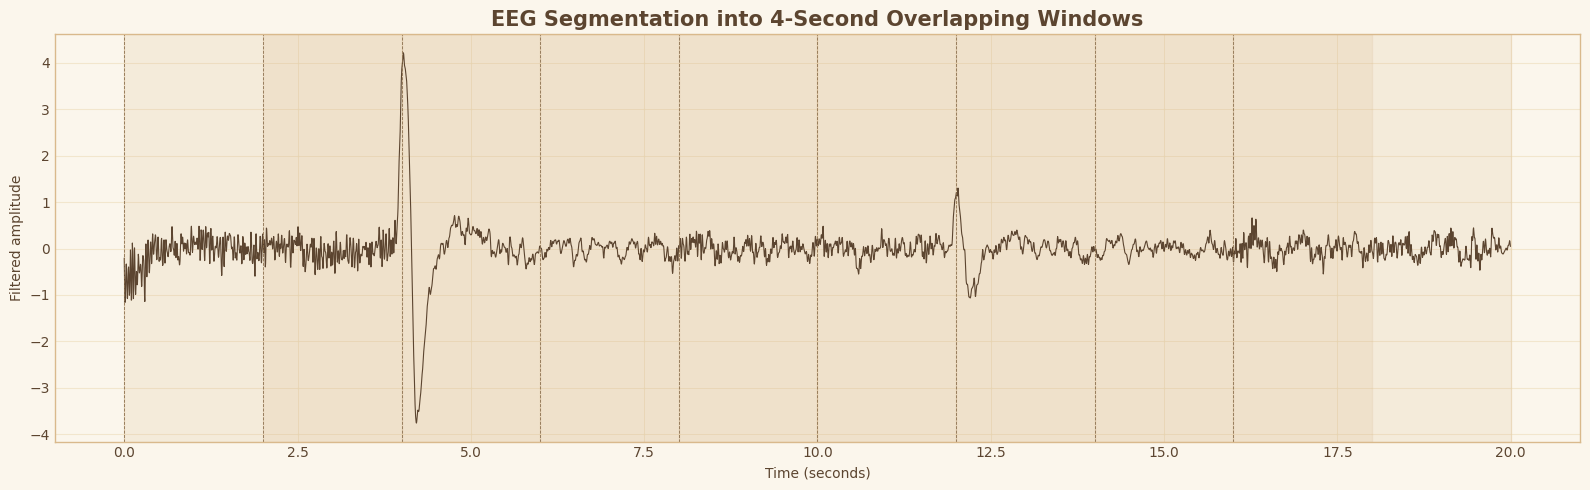

In [34]:
DISPLAY_SECONDS = 20

n = min(
    int(DISPLAY_SECONDS * FS),
    len(filtered_signal)
)

display_signal = filtered_signal[:n]

time_axis = np.arange(n) / FS

plt.figure(figsize=(16, 5))

plt.plot(
    time_axis,
    display_signal,
    linewidth=0.8,
    color=CANVA_DARK_BROWN
)

# Draw window boundaries
start = 0
window_number = 0

while start + WINDOW_SAMPLES <= n:

    end = start + WINDOW_SAMPLES

    plt.axvspan(
        start / FS,
        end / FS,
        alpha=0.18,
        color=CANVA_TAN
    )

    plt.axvline(
        start / FS,
        linestyle="--",
        linewidth=0.6,
        color=CANVA_BROWN
    )

    window_number += 1

    start += STEP_SAMPLES

plt.title(
    "EEG Segmentation into 4-Second Overlapping Windows"
)

plt.xlabel(
    "Time (seconds)"
)

plt.ylabel(
    "Filtered amplitude"
)

plt.tight_layout()
plt.show()

In [35]:
window_mean = np.mean(
    windows,
    axis=1
)

window_std = np.std(
    windows,
    axis=1
)

window_rms = np.sqrt(
    np.mean(
        windows ** 2,
        axis=1
    )
)

window_peak = np.max(
    np.abs(windows),
    axis=1
)

window_statistics = pd.DataFrame({
    "Mean": window_mean,
    "Std": window_std,
    "RMS": window_rms,
    "Peak": window_peak
})

display(
    window_statistics.describe().round(5)
)

,Mean,Std,RMS,Peak
count,71.00000,71.00000,71.00000,71.00000
mean,-0.00086,0.32466,0.32486,1.42639
std,0.01121,0.19662,0.19662,1.04412
min,-0.02797,0.15831,0.15832,0.48002
25%,-0.00537,0.20463,0.20591,0.73080
50%,-0.00039,0.26486,0.26487,0.99168
75%,0.00281,0.32929,0.32932,1.90691
max,0.03152,0.97910,0.97910,4.21698


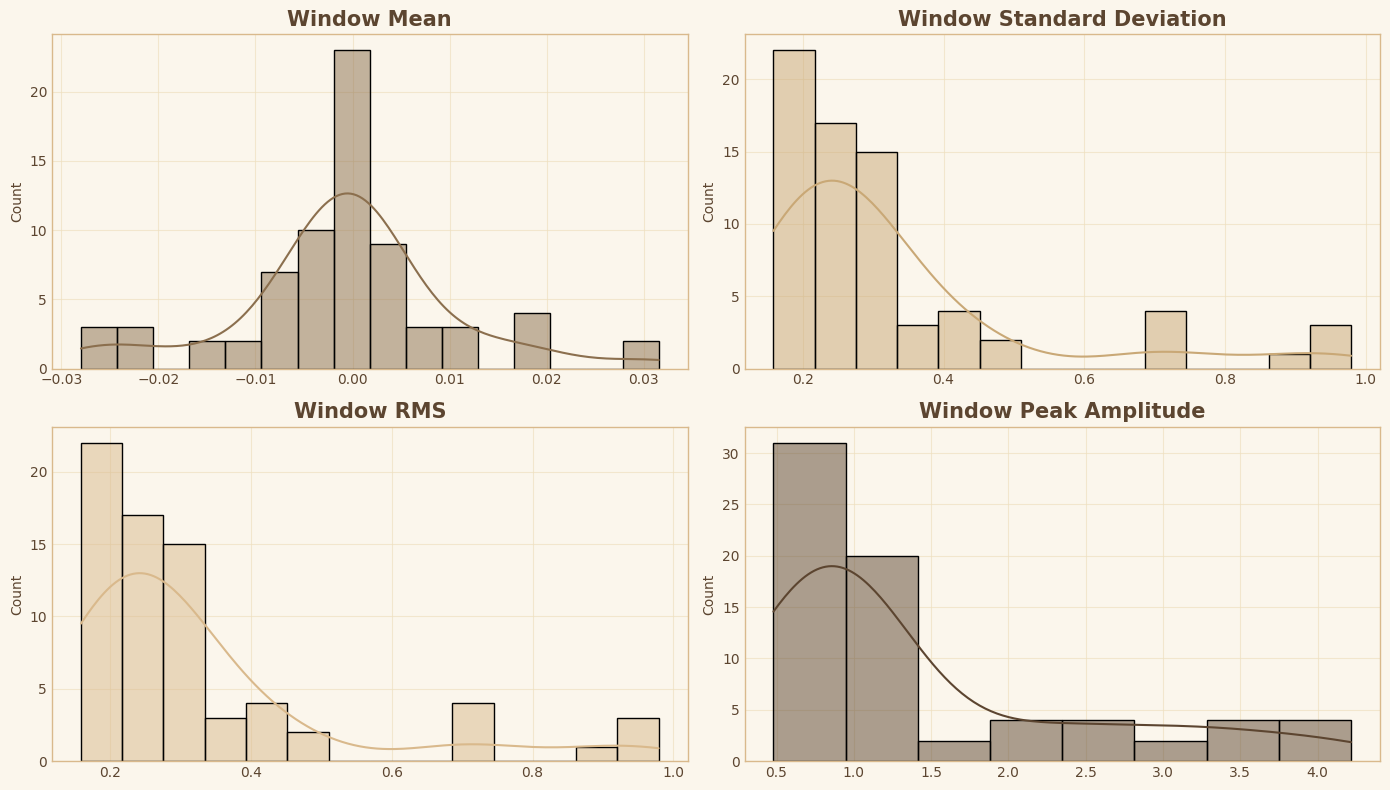

In [36]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 8)
)

sns.histplot(
    window_mean,
    kde=True,
    ax=axes[0, 0],
    color=CANVA_BROWN
)

axes[0, 0].set_title(
    "Window Mean"
)

sns.histplot(
    window_std,
    kde=True,
    ax=axes[0, 1],
    color=CANVA_GOLD
)

axes[0, 1].set_title(
    "Window Standard Deviation"
)

sns.histplot(
    window_rms,
    kde=True,
    ax=axes[1, 0],
    color=CANVA_TAN
)

axes[1, 0].set_title(
    "Window RMS"
)

sns.histplot(
    window_peak,
    kde=True,
    ax=axes[1, 1],
    color=CANVA_DARK_BROWN
)

axes[1, 1].set_title(
    "Window Peak Amplitude"
)

plt.tight_layout()
plt.show()

In [37]:
statistics_comparison = pd.DataFrame({
    "Metric": [
        "Mean",
        "Std",
        "RMS",
        "Peak-to-Peak"
    ],

    "Before Filtering": [
        np.mean(eeg_signal),
        np.std(eeg_signal),
        np.sqrt(np.mean(eeg_signal ** 2)),
        np.ptp(eeg_signal)
    ],

    "After Filtering": [
        np.mean(filtered_signal),
        np.std(filtered_signal),
        np.sqrt(np.mean(filtered_signal ** 2)),
        np.ptp(filtered_signal)
    ]
})

display(
    statistics_comparison.round(6)
)

,Metric,Before Filtering,After Filtering
0,Mean,-0.001448,-0.001179
1,Std,0.435843,0.378102
2,RMS,0.435846,0.378104
3,Peak-to-Peak,8.118000,7.978660


In [38]:
def calculate_spectral_entropy(
    x,
    fs
):

    f, psd = welch(
        x,
        fs=fs,
        nperseg=min(2048, len(x))
    )

    psd = np.maximum(
        psd,
        1e-12
    )

    probability = (
        psd /
        np.sum(psd)
    )

    entropy = -np.sum(
        probability *
        np.log2(probability)
    )

    return entropy


entropy = calculate_spectral_entropy(
    filtered_signal,
    FS
)

print(
    f"Spectral entropy: {entropy:.5f}"
)

Spectral entropy: 5.87056


In [39]:
def hjorth_parameters(x):

    activity = np.var(x)

    dx = np.diff(x)
    ddx = np.diff(dx)

    mobility = np.sqrt(
        np.var(dx) /
        (activity + 1e-12)
    )

    mobility_derivative = np.sqrt(
        np.var(ddx) /
        (np.var(dx) + 1e-12)
    )

    complexity = (
        mobility_derivative /
        (mobility + 1e-12)
    )

    return (
        activity,
        mobility,
        complexity
    )


activity, mobility, complexity = hjorth_parameters(
    filtered_signal
)

print("=" * 60)
print("HJORTH PARAMETERS")
print("=" * 60)

print(f"Activity   : {activity:.6f}")
print(f"Mobility   : {mobility:.6f}")
print(f"Complexity : {complexity:.6f}")

HJORTH PARAMETERS
Activity   : 0.142961
Mobility   : 0.220205
Complexity : 3.393611


In [40]:
from scipy.stats import skew, kurtosis

def extract_features_from_window(
    x,
    fs=256
):

    features = {}

    # Time-domain
    features["mean"] = np.mean(x)
    features["std"] = np.std(x)
    features["variance"] = np.var(x)
    features["rms"] = np.sqrt(np.mean(x ** 2))
    features["min"] = np.min(x)
    features["max"] = np.max(x)
    features["peak_to_peak"] = np.ptp(x)

    features["skewness"] = skew(x)
    features["kurtosis"] = kurtosis(x)

    # Zero crossing rate
    zero_crossings = np.sum(
        np.diff(np.signbit(x))
    )

    features["zero_crossing_rate"] = (
        zero_crossings / len(x)
    )

    # Hjorth
    activity, mobility, complexity = (
        hjorth_parameters(x)
    )

    features["hjorth_activity"] = activity
    features["hjorth_mobility"] = mobility
    features["hjorth_complexity"] = complexity

    # Spectral features
    f, psd = welch(
        x,
        fs=fs,
        nperseg=min(1024, len(x))
    )

    total_power = np.trapezoid(
        psd,
        f
    )

    features["total_power"] = total_power

    # Band powers
    for band, (low, high) in EEG_BANDS.items():

        mask = (
            (f >= low) &
            (f <= high)
        )

        power = np.trapezoid(
            psd[mask],
            f[mask]
        )

        features[
            f"{band.lower()}_power"
        ] = power

        features[
            f"{band.lower()}_relative_power"
        ] = power / (
            total_power + 1e-12
        )

    # Spectral entropy
    features[
        "spectral_entropy"
    ] = calculate_spectral_entropy(
        x,
        fs
    )

    return features

In [41]:
feature_rows = []

for window in tqdm(
    windows,
    desc="Extracting EEG features"
):

    feature_rows.append(
        extract_features_from_window(
            window,
            FS
        )
    )

features_df = pd.DataFrame(
    feature_rows
)

print(
    f"Feature matrix shape: {features_df.shape}"
)

display(
    features_df.head()
)

Extracting EEG features: 100%|██████████| 71/71 [00:00<00:00, 595.35it/s]

Feature matrix shape: (71, 25)


,mean,std,variance,rms,min,max,peak_to_peak,skewness,kurtosis,zero_crossing_rate,...,delta_relative_power,theta_power,theta_relative_power,alpha_power,alpha_relative_power,beta_power,beta_relative_power,gamma_power,gamma_relative_power,spectral_entropy
0,-0.020911,0.381048,0.145198,0.381622,-1.159834,3.592404,4.752237,3.130290,26.109215,0.165039,...,0.156833,0.004508,0.104135,0.001340,0.030965,0.016744,0.386789,0.011609,0.268161,6.676556
1,-0.001814,0.979102,0.958640,0.979103,-3.761683,4.216977,7.978660,0.333664,8.152960,0.093750,...,0.956422,0.053078,0.022492,0.007292,0.003090,0.009392,0.003980,0.006532,0.002768,3.871262
2,-0.023121,0.936530,0.877088,0.936815,-3.761683,4.216977,7.978660,0.212305,9.596774,0.044922,...,0.480999,0.009842,0.247447,0.002279,0.057287,0.002715,0.068248,0.000884,0.022217,4.750067
3,0.001083,0.158314,0.025063,0.158318,-0.533796,0.384541,0.918337,-0.301797,-0.508927,0.091797,...,0.477156,0.005049,0.169715,0.001317,0.044283,0.005002,0.168130,0.003976,0.133633,5.964745
4,0.018072,0.186720,0.034864,0.187593,-0.551121,1.133361,1.684482,1.114652,5.844187,0.119141,...,0.371100,0.006788,0.261894,0.001341,0.051751,0.004399,0.169734,0.003051,0.117712,6.151024


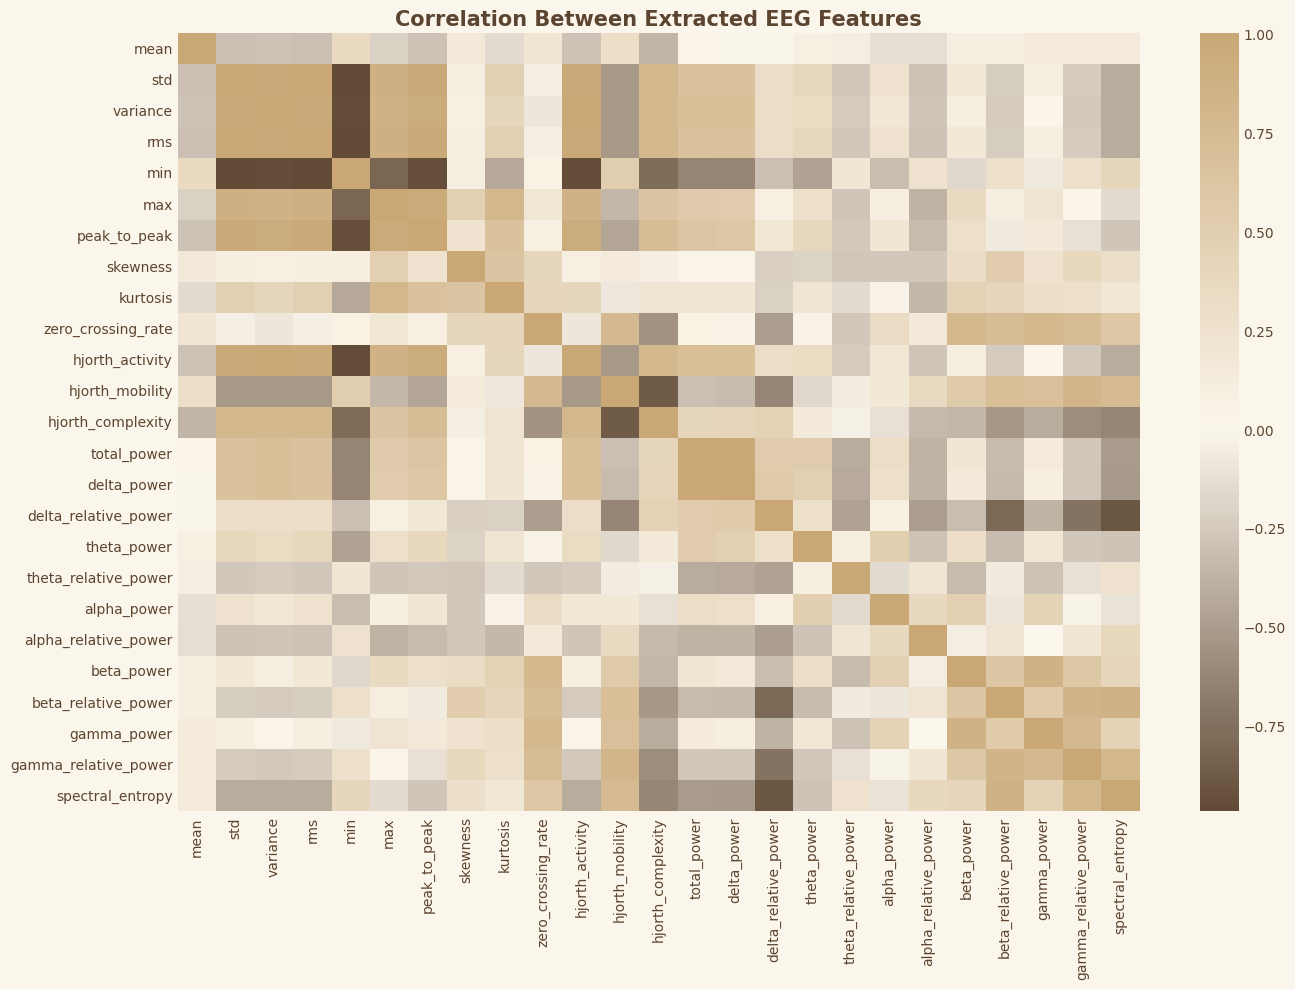

In [42]:
plt.figure(figsize=(14, 10))

correlation = features_df.corr()

sns.heatmap(
    correlation,
    cmap=CANVA_DIV_CMAP,
    center=0,
    square=False
)

plt.title(
    "Correlation Between Extracted EEG Features"
)

plt.tight_layout()
plt.show()

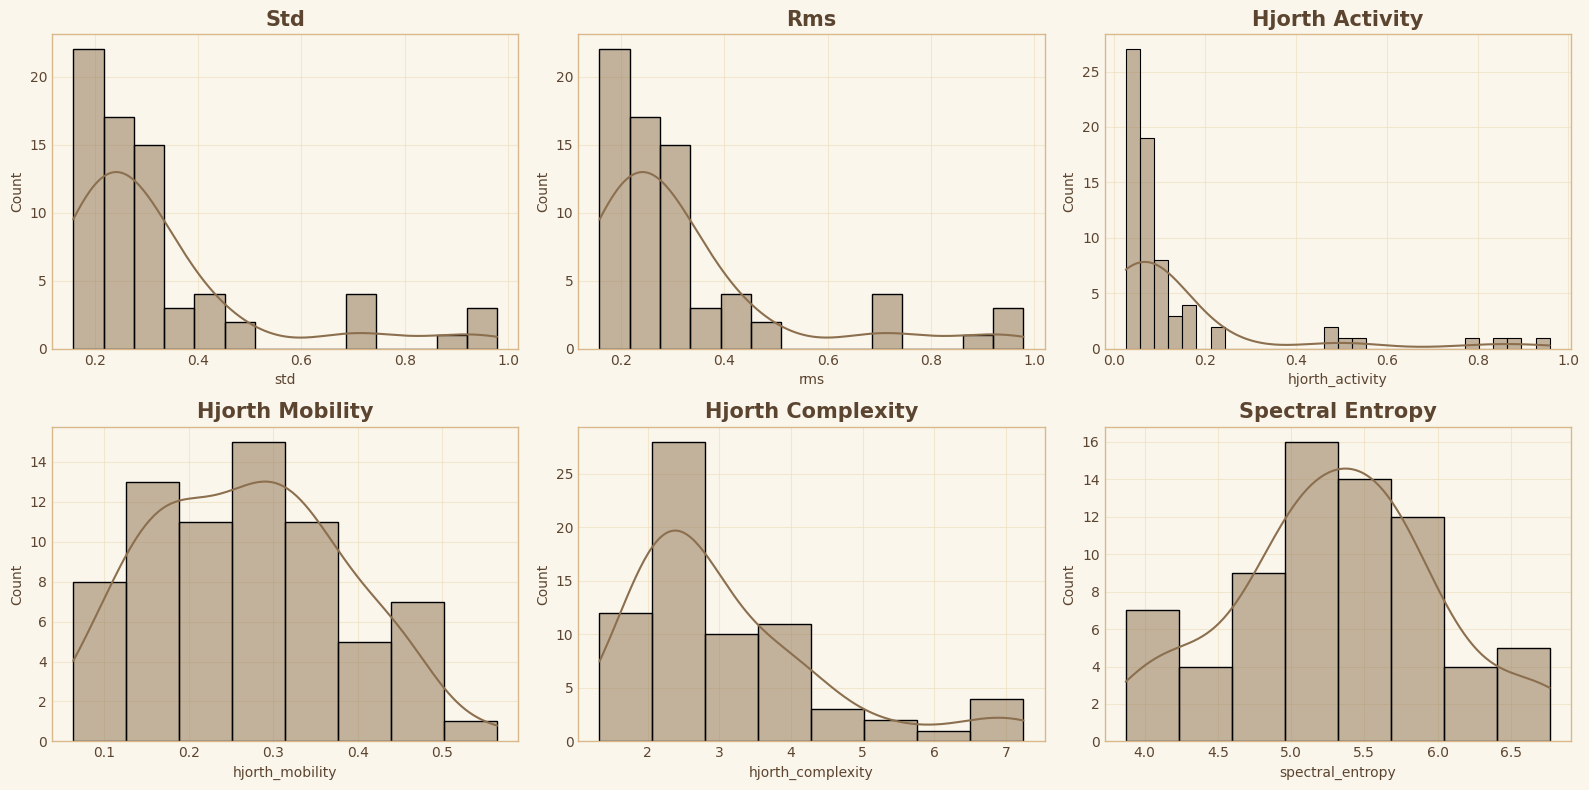

In [43]:
selected_features = [
    "std",
    "rms",
    "hjorth_activity",
    "hjorth_mobility",
    "hjorth_complexity",
    "spectral_entropy"
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 8)
)

for ax, feature in zip(
    axes.ravel(),
    selected_features
):

    sns.histplot(
        features_df[feature],
        kde=True,
        ax=ax,
        color=CANVA_BROWN
    )

    ax.set_title(
        feature.replace("_", " ").title()
    )

plt.tight_layout()
plt.show()

In [44]:
def zscore_signal(x):

    mean = np.mean(x)
    std = np.std(x)

    return (
        x - mean
    ) / (
        std + 1e-8
    )


normalized_signal = zscore_signal(
    filtered_signal
)

print("Normalization completed.")

print(
    f"Original mean/std : "
    f"{np.mean(filtered_signal):.5f} / "
    f"{np.std(filtered_signal):.5f}"
)

print(
    f"Normalized mean/std: "
    f"{np.mean(normalized_signal):.5f} / "
    f"{np.std(normalized_signal):.5f}"
)

Normalization completed.
Original mean/std : -0.00118 / 0.37810
Normalized mean/std: 0.00000 / 1.00000


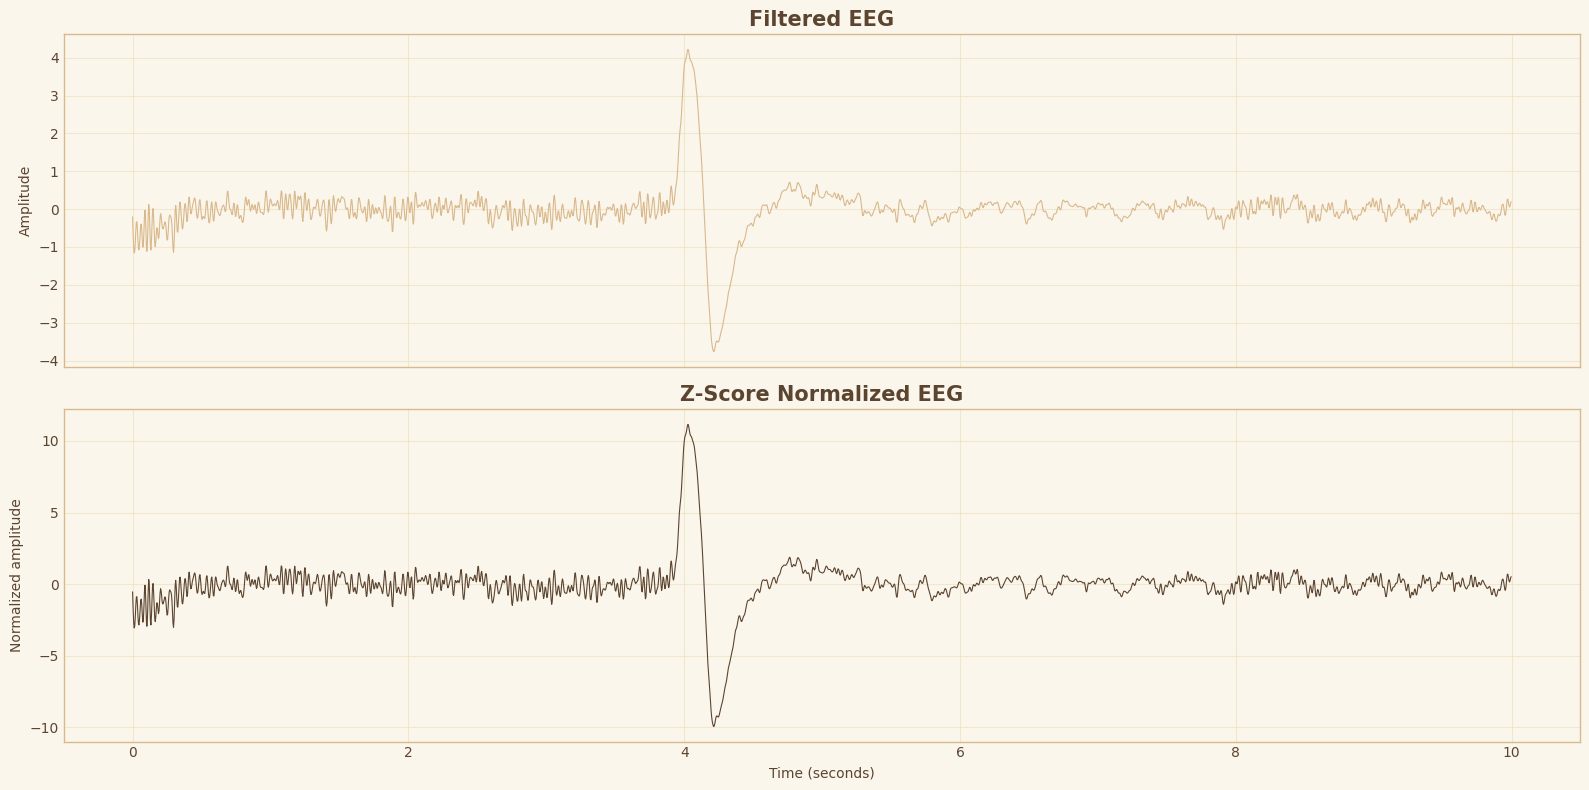

In [45]:
n = min(
    10 * FS,
    len(filtered_signal)
)

t = np.arange(n) / FS

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 8),
    sharex=True
)

axes[0].plot(
    t,
    filtered_signal[:n],
    linewidth=0.8,
    color=CANVA_TAN
)

axes[0].set_title(
    "Filtered EEG"
)

axes[0].set_ylabel(
    "Amplitude"
)

axes[1].plot(
    t,
    normalized_signal[:n],
    linewidth=0.8,
    color=CANVA_DARK_BROWN
)

axes[1].set_title(
    "Z-Score Normalized EEG"
)

axes[1].set_xlabel(
    "Time (seconds)"
)

axes[1].set_ylabel(
    "Normalized amplitude"
)

plt.tight_layout()
plt.show()

In [46]:
print("=" * 60)
print("DATA SPLITTING STRATEGY")
print("=" * 60)

print(
    "No patient/subject metadata is available."
)

print(
    "Therefore, we split original observations "
    "before window generation."
)

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df[TARGET_COL]
    if df[TARGET_COL].nunique() > 1
    else None
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df[TARGET_COL]
    if temp_df[TARGET_COL].nunique() > 1
    else None
)

print()
print(f"Train rows: {len(train_df):,}")
print(f"Val rows  : {len(val_df):,}")
print(f"Test rows : {len(test_df):,}")

DATA SPLITTING STRATEGY
No patient/subject metadata is available.
Therefore, we split original observations before window generation.

Train rows: 7,863
Val rows  : 1,685
Test rows : 1,685


In [47]:
split_summary = pd.DataFrame({
    "Train": train_df[TARGET_COL].value_counts(normalize=True),
    "Validation": val_df[TARGET_COL].value_counts(normalize=True),
    "Test": test_df[TARGET_COL].value_counts(normalize=True)
}).fillna(0) * 100

display(
    split_summary.round(2)
)

,Train,Validation,Test
target,,,
0,87.23,87.24,87.24
1,12.77,12.76,12.76


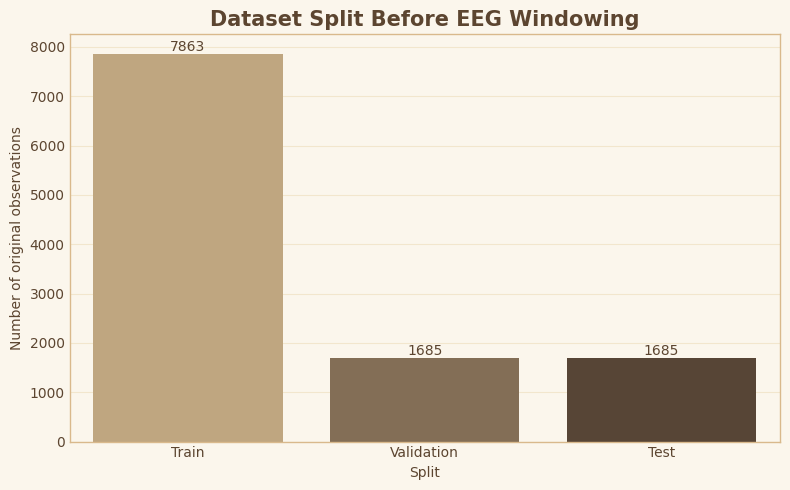

In [48]:
split_counts = pd.DataFrame({
    "Split": [
        "Train",
        "Validation",
        "Test"
    ],
    "Rows": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=split_counts,
    x="Split",
    y="Rows",
    palette=[CANVA_GOLD, CANVA_BROWN, CANVA_DARK_BROWN]
)

plt.title(
    "Dataset Split Before EEG Windowing"
)

plt.ylabel(
    "Number of original observations"
)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [49]:
def preprocess_dataframe(
    dataframe,
    signal_columns,
    fs=256,
    lowcut=0.5,
    highcut=45.0,
    filter_order=4,
    window_seconds=4,
    overlap=0.5
):

    window_samples = int(
        fs * window_seconds
    )

    step_samples = int(
        window_samples * (1 - overlap)
    )

    X_windows = []
    y_windows = []

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc="Processing recordings"
    ):

        x = row[
            signal_columns
        ].values.astype(np.float32)

        # Filtering
        x_filtered = bandpass_filter(
            x,
            lowcut,
            highcut,
            fs,
            filter_order
        )

        # Normalization
        x_filtered = zscore_signal(
            x_filtered
        )

        # Windowing
        windows = segment_signal(
            x_filtered,
            window_samples,
            step_samples
        )

        # Store windows
        X_windows.append(
            windows
        )

        # Same label for all windows from this source row
        y_windows.extend(
            [row[TARGET_COL]] *
            len(windows)
        )

    if len(X_windows) == 0:

        return (
            np.empty(
                (0, window_samples),
                dtype=np.float32
            ),
            np.empty(
                (0,),
                dtype=np.int64
            )
        )

    X_windows = np.concatenate(
        X_windows,
        axis=0
    )

    y_windows = np.asarray(
        y_windows
    )

    return (
        X_windows,
        y_windows
    )

In [50]:
X_train, y_train = preprocess_dataframe(
    train_df,
    SIGNAL_COLUMNS,
    fs=FS,
    lowcut=LOWCUT,
    highcut=HIGHCUT,
    filter_order=FILTER_ORDER,
    window_seconds=WINDOW_SECONDS,
    overlap=OVERLAP
)

print(
    "Training tensor:",
    X_train.shape
)

print(
    "Training labels:",
    y_train.shape
)

Processing recordings: 100%|██████████| 7863/7863 [02:22<00:00, 55.11it/s]


Training tensor: (558273, 1024)
Training labels: (558273,)


In [51]:
X_val, y_val = preprocess_dataframe(
    val_df,
    SIGNAL_COLUMNS,
    fs=FS,
    lowcut=LOWCUT,
    highcut=HIGHCUT,
    filter_order=FILTER_ORDER,
    window_seconds=WINDOW_SECONDS,
    overlap=OVERLAP
)

print(
    "Validation tensor:",
    X_val.shape
)

print(
    "Validation labels:",
    y_val.shape
)

Processing recordings: 100%|██████████| 1685/1685 [00:24<00:00, 69.13it/s]


Validation tensor: (119635, 1024)
Validation labels: (119635,)


In [52]:
X_test, y_test = preprocess_dataframe(
    test_df,
    SIGNAL_COLUMNS,
    fs=FS,
    lowcut=LOWCUT,
    highcut=HIGHCUT,
    filter_order=FILTER_ORDER,
    window_seconds=WINDOW_SECONDS,
    overlap=OVERLAP
)

print(
    "Test tensor:",
    X_test.shape
)

print(
    "Test labels:",
    y_test.shape
)

Processing recordings: 100%|██████████| 1685/1685 [00:23<00:00, 70.53it/s]


Test tensor: (119635, 1024)
Test labels: (119635,)


In [53]:
print("=" * 60)
print("WINDOW-LEVEL DATASET")
print("=" * 60)

for name, y in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:

    unique, counts = np.unique(
        y,
        return_counts=True
    )

    print(f"\n{name}")

    for label, count in zip(
        unique,
        counts
    ):

        print(
            f"  Class {label}: {count:,}"
        )

WINDOW-LEVEL DATASET

Train
  Class 0.0: 486,989
  Class 1.0: 71,284

Validation
  Class 0.0: 104,370
  Class 1.0: 15,265

Test
  Class 0.0: 104,370
  Class 1.0: 15,265


In [54]:
print("=" * 60)
print("FINAL MODEL INPUT")
print("=" * 60)

print(
    f"X_train : {X_train.shape}"
)

print(
    f"X_val   : {X_val.shape}"
)

print(
    f"X_test  : {X_test.shape}"
)

print()
print(
    "Each sample = "
    f"{WINDOW_SECONDS} seconds × "
    f"{WINDOW_SAMPLES} temporal points"
)

FINAL MODEL INPUT
X_train : (558273, 1024)
X_val   : (119635, 1024)
X_test  : (119635, 1024)

Each sample = 4 seconds × 1024 temporal points


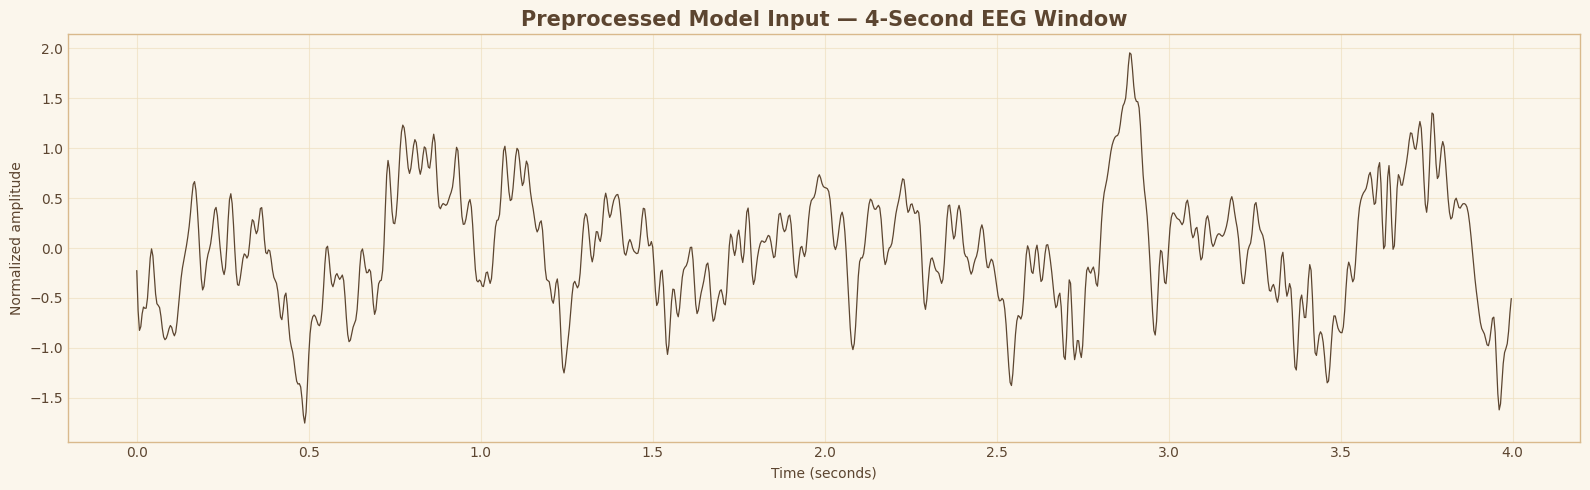

In [55]:
if len(X_train) > 0:

    plt.figure(figsize=(16, 5))

    t = np.arange(
        WINDOW_SAMPLES
    ) / FS

    plt.plot(
        t,
        X_train[0],
        linewidth=0.9,
        color=CANVA_DARK_BROWN
    )

    plt.title(
        f"Preprocessed Model Input — "
        f"{WINDOW_SECONDS}-Second EEG Window"
    )

    plt.xlabel(
        "Time (seconds)"
    )

    plt.ylabel(
        "Normalized amplitude"
    )

    plt.tight_layout()
    plt.show()

In [56]:
OUTPUT_DIR = r"C:\Users\devgo\OneDrive\Desktop\mini project\processed"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "X_train.npy"
    ),
    X_train
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "y_train.npy"
    ),
    y_train
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "X_val.npy"
    ),
    X_val
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "y_val.npy"
    ),
    y_val
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "X_test.npy"
    ),
    X_test
)

np.save(
    os.path.join(
        OUTPUT_DIR,
        "y_test.npy"
    ),
    y_test
)

print(
    f"Processed data saved to:\n{OUTPUT_DIR}"
)

Processed data saved to:
C:\Users\devgo\OneDrive\Desktop\mini project\processed


In [57]:
print()
print("=" * 70)
print("FINAL PREPROCESSING REPORT")
print("=" * 70)

print(f"Original observations       : {len(df):,}")
print(f"Signal samples / observation: {len(SIGNAL_COLUMNS):,}")
print(f"Assumed sampling rate       : {FS} Hz")
print(f"Observation duration        : {len(SIGNAL_COLUMNS)/FS:.2f} sec")

print()
print("PREPROCESSING")

print(f"Bandpass filter              : {LOWCUT}–{HIGHCUT} Hz")
print(f"Filter order                 : {FILTER_ORDER}")
print(f"Normalization                : Per-observation z-score")

print()
print("SEGMENTATION")

print(f"Window duration              : {WINDOW_SECONDS} sec")
print(f"Window samples               : {WINDOW_SAMPLES}")
print(f"Overlap                     : {OVERLAP * 100:.0f}%")
print(f"Step size                   : {STEP_SAMPLES} samples")

print()
print("SPLIT")

print(f"Training observations        : {len(train_df):,}")
print(f"Validation observations      : {len(val_df):,}")
print(f"Testing observations         : {len(test_df):,}")

print()
print("FINAL TENSORS")

print(f"X_train                      : {X_train.shape}")
print(f"X_val                        : {X_val.shape}")
print(f"X_test                       : {X_test.shape}")

print()
print("IMPORTANT LIMITATION")
print("-" * 70)
print(
    "No patient/subject identifiers are available in the CSV."
)
print(
    "Therefore, patient-independent evaluation cannot be claimed "
    "from this dataset representation."
)


FINAL PREPROCESSING REPORT
Original observations       : 11,233
Signal samples / observation: 36,864
Assumed sampling rate       : 256 Hz
Observation duration        : 144.00 sec

PREPROCESSING
Bandpass filter              : 0.5–45.0 Hz
Filter order                 : 4
Normalization                : Per-observation z-score

SEGMENTATION
Window duration              : 4 sec
Window samples               : 1024
Overlap                     : 50%
Step size                   : 512 samples

SPLIT
Training observations        : 7,863
Validation observations      : 1,685
Testing observations         : 1,685

FINAL TENSORS
X_train                      : (558273, 1024)
X_val                        : (119635, 1024)
X_test                       : (119635, 1024)

IMPORTANT LIMITATION
----------------------------------------------------------------------
No patient/subject identifiers are available in the CSV.
Therefore, patient-independent evaluation cannot be claimed from this dataset representati